# Online Retail Sales Dataset Analysis

## Importing libraries
The following libraries are used throughout the project:
- **pandas** – loading, cleaning and summarising tabular data.
- **numpy** – numerical calculations.
- **matplotlib** and **seaborn** – static visualisations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Loading the data

In [2]:
df = pd.read_excel('Online Retail.xlsx')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


The data has loaded correctly: each row is one product on an invoice, showing the quantity, unit price, customer and country. The next section assesses the quality of this raw data before any cleaning is done.

## Data quality assessment
The raw data is checked for problems before cleaning. Nothing is changed in this section.

In [3]:
df.shape

(541909, 8)

The dataset has **541,909 rows** and **8 columns**.

In [4]:
df.dtypes

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

`InvoiceDate` is already a date, so it can be used for time analysis. `CustomerID` is a decimal number because it has missing values;

In [5]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


`Quantity` and `UnitPrice` both have **negative minimums** and **very large maximums**, so the data contains invalid rows and outliers. The data runs from **1 Dec 2010 to 9 Dec 2011**, so December 2011 is incomplete.

In [6]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

`CustomerID` is missing in **135,080 rows** and `Description` in **1,454 rows**.

In [7]:
df.shape[0] - df.drop_duplicates().shape[0]

5268

There are **5,268 duplicate rows**, which would count the same sale twice.

In [8]:
df[df['Quantity'] < 0].shape

(10624, 8)

There are **10,624 rows with a negative quantity**. These are cancelled orders or stock adjustments, not real sales.

In [9]:
df[df['UnitPrice'] <= 0].shape

(2517, 8)

There are **2,517 rows with a price of £0 or less**, which add no real revenue.

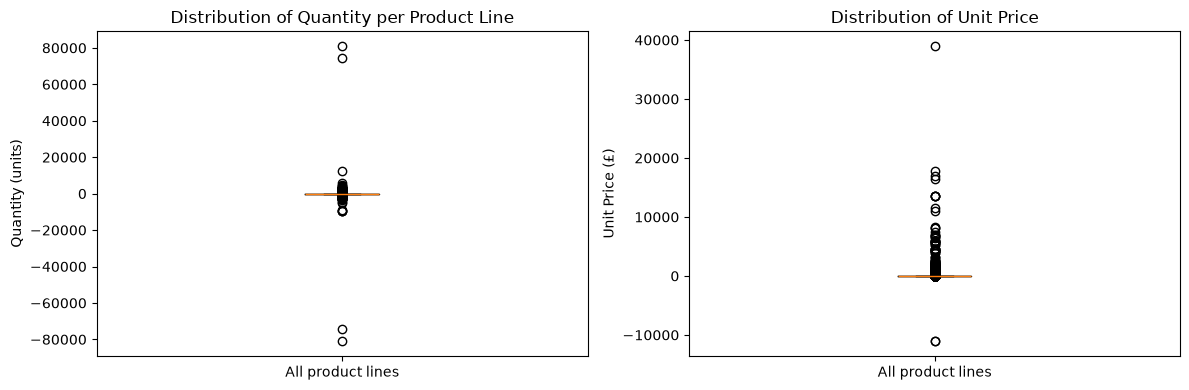

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].boxplot(df['Quantity'])
axes[0].set_title('Distribution of Quantity per Product Line')
axes[0].set_ylabel('Quantity (units)')
axes[0].set_xticklabels(['All product lines'])

axes[1].boxplot(df['UnitPrice'])
axes[1].set_title('Distribution of Unit Price')
axes[1].set_ylabel('Unit Price (£)')
axes[1].set_xticklabels(['All product lines'])

plt.tight_layout()
plt.show()

A boxplot shows the normal range of values and marks extreme values as dots. Most values sit close to zero, but a few are extremely far away. These **outliers** would distort averages and charts.

### Summary of issues
| Issue | Rows |
|---|---|
| Missing `CustomerID` | 135,080 |
| Missing `Description` | 1,454 |
| Duplicate rows | 5,268 |
| Negative quantities | 10,624 |
| Price of £0 or less | 2,517 |
| Outliers in `Quantity` and `UnitPrice` | a few extreme values |

These issues are fixed in the next section.

## Data cleaning and preparation
Each issue from the assessment is fixed here. The cleaning is done on a copy of the data, so the original stays unchanged for comparison.

In [11]:
df_clean = df.copy()

### Missing values
- **`CustomerID`:** filled with `0`, meaning "unknown customer". These are real sales, and removing about 25% of the data would make revenue, product and country figures too low. Customer-level analysis will leave out `CustomerID = 0`.
- **`Description`:** rows are removed. Without a name the product cannot be identified, and it is only 0.3% of the data.

`CustomerID` is filled first, so `dropna()` only removes the rows with no description.

In [12]:
df_clean['CustomerID'] = df_clean['CustomerID'].fillna(0)
df_clean = df_clean.dropna()

In [13]:
df_clean.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [14]:
df_clean.shape

(540455, 8)

No missing values remain. 1,454 rows without a description were removed, leaving **540,455 rows**.

### Duplicates
Exact duplicate rows are removed because they would count the same sale twice.

In [15]:
df_clean = df_clean.drop_duplicates()
df_clean.shape

(535187, 8)

**5,268 duplicate rows** were removed, leaving **535,187 rows**.

### Cancelled orders and negative quantities
Only rows with a quantity above zero are kept. Negative quantities are cancelled orders or stock adjustments, not real sales, so they would wrongly reduce revenue.

In [16]:
df_clean = df_clean[df_clean['Quantity'] > 0]
df_clean.shape

(525462, 8)

**9,725 rows** were removed, leaving **525,462 rows**.

### Zero and negative prices
Only rows with a price above zero are kept. A price of £0 or less is a free item, an error or an accounting entry, and adds no real revenue.

In [17]:
df_clean = df_clean[df_clean['UnitPrice'] > 0]
df_clean.shape

(524878, 8)

**584 rows** were removed, leaving **524,878 rows**.

In [18]:
df_clean[['Quantity', 'UnitPrice']].describe()

,Quantity,UnitPrice
count,524878.000000,524878.000000
mean,10.616600,3.922573
std,156.280031,36.093028
min,1.000000,0.001000
25%,1.000000,1.250000
50%,4.000000,2.080000
75%,11.000000,4.130000
max,80995.000000,13541.330000


The minimum quantity is now **1** and the minimum price is above **£0**, so all invalid rows are gone. The maximums are still very large, so the outliers are handled next.